In [1]:
# IMPORTAR LIBRERÍAS
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Scikit-learn: librería de Machine Learning
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configurar semilla para reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configurar estilo de matplotlib
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print("Librerías importadas")
print(f"   - pandas: {pd.__version__}")
print(f"   - numpy: {np.__version__}")
print(f"   - scikit-learn: {__import__('sklearn').__version__}")
print(f"\nSemilla de reproducibilidad: {RANDOM_STATE}")


Librerías importadas
   - pandas: 2.2.3
   - numpy: 2.1.3
   - scikit-learn: 1.6.1

Semilla de reproducibilidad: 42


In [2]:
# CARGAR demanda_diaria.csv Y ORDENAR POR CRONOLOGIA
if not os.path.exists("demanda_diaria.csv"):
    from google.colab import files
    print("Selecciona el archivo demanda_diaria.csv")
    files.upload()

df = pd.read_csv("demanda_diaria.csv", parse_dates=["fecha"])
df = df.sort_values("fecha").reset_index(drop=True) # Orden cronologico

# Variables de calendario
df["dia_semana"] = df["fecha"].dt.dayofweek  # 0=lunes, 6=domingo
df["mes"] = df["fecha"].dt.month

# Variables de calendario
print(f"Dataset cargado: {df.shape[0]} días, {df.shape[1]} columnas")
print(f"\nPrimeras 5 filas:")
print(df.head().to_string())


Selecciona el archivo demanda_diaria.csv


Saving demanda_diaria.csv to demanda_diaria.csv
Dataset cargado: 180 días, 5 columnas

Primeras 5 filas:
       fecha  demanda_kwh  evento_programado  dia_semana  mes
0 2026-01-01     17856.31                  1           3    1
1 2026-01-02     17379.10                  1           4    1
2 2026-01-03     15720.70                  0           5    1
3 2026-01-04     15694.05                  0           6    1
4 2026-01-05     16505.77                  0           0    1


In [3]:
# VERIFICAR CALIDAD DEL DATASET
print("INFORMACIÓN DEL DATASET:")
print("=" * 50)
df.info()

print("\nVALORES NULOS POR COLUMNA:")
print(df.isnull().sum())

print(f"\nFECHAS DUPLICADAS: {df['fecha'].duplicated().sum()}")
print(f"¿Fechas en orden cronológico? {df['fecha'].is_monotonic_increasing}")

print(f"\nRANGO TEMPORAL:")
print(f"  Desde: {df['fecha'].min()}")
print(f"  Hasta: {df['fecha'].max()}")

print(f"\nESTADISTICAS DE demanda_kwh (variable objetivo y):")
print(df['demanda_kwh'].describe().to_string())


INFORMACIÓN DEL DATASET:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   fecha              180 non-null    datetime64[ns]
 1   demanda_kwh        180 non-null    float64       
 2   evento_programado  180 non-null    int64         
 3   dia_semana         180 non-null    int32         
 4   mes                180 non-null    int32         
dtypes: datetime64[ns](1), float64(1), int32(2), int64(1)
memory usage: 5.8 KB

VALORES NULOS POR COLUMNA:
fecha                0
demanda_kwh          0
evento_programado    0
dia_semana           0
mes                  0
dtype: int64

FECHAS DUPLICADAS: 0
¿Fechas en orden cronológico? True

RANGO TEMPORAL:
  Desde: 2026-01-01 00:00:00
  Hasta: 2026-06-29 00:00:00

ESTADISTICAS DE demanda_kwh (variable objetivo y):
count      180.000000
mean     17482.592611
std       1042.291145
m

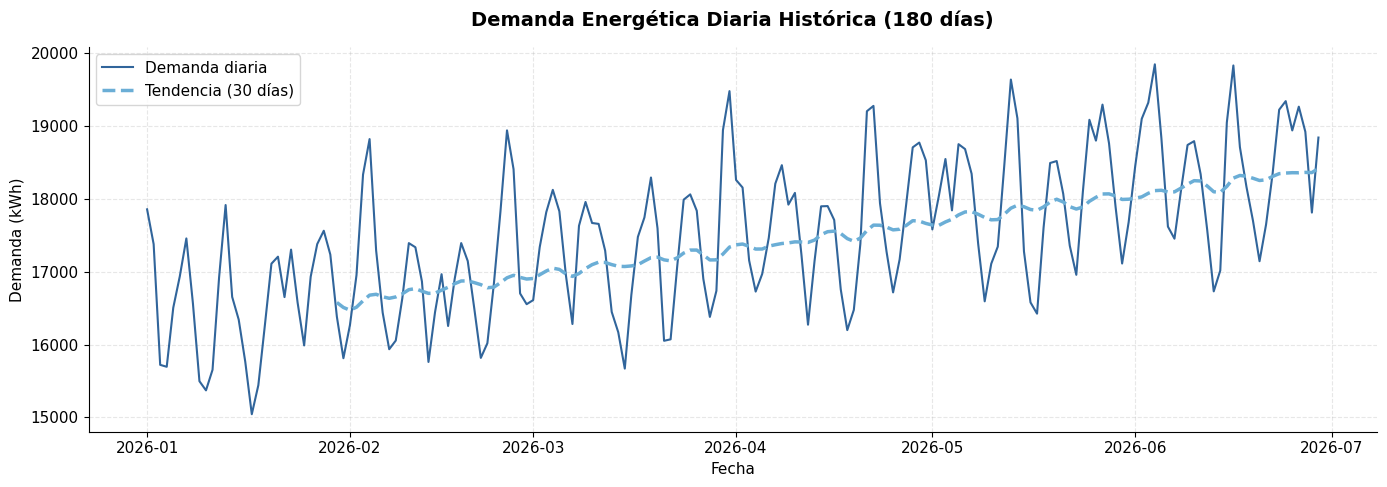


OBSERVACIONES DE LA SERIE:
   • Demanda mínima: 15,042.51 kWh
   • Demanda máxima: 19,847.82 kWh
   • Demanda promedio: 17,482.59 kWh


In [4]:
# GRÁFICO 1: Serie histórica de demanda
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df["fecha"], df["demanda_kwh"],
        color='#1a5490', linewidth=1.5, alpha=0.9, label='Demanda diaria')

# Linea de tendencia media movil de 30 dias
df['tendencia_30'] = df['demanda_kwh'].rolling(window=30).mean()
ax.plot(df["fecha"], df['tendencia_30'],
        color='#6baed6', linewidth=2.5, linestyle='--', label='Tendencia (30 días)')

ax.set_title('Demanda Energética Diaria Histórica (180 días)',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Fecha', fontsize=11)
ax.set_ylabel('Demanda (kWh)', fontsize=11)
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

print("\nOBSERVACIONES DE LA SERIE:")
print(f"   • Demanda mínima: {df['demanda_kwh'].min():,.2f} kWh")
print(f"   • Demanda máxima: {df['demanda_kwh'].max():,.2f} kWh")
print(f"   • Demanda promedio: {df['demanda_kwh'].mean():,.2f} kWh")


DEMANDA PROMEDIO POR EVENTO PROGRAMADO:
   Sin evento (0): 17,281.11 kWh
   Con evento (1): 18,347.78 kWh

DIFERENCIA: 1,066.67 kWh
IMPACTO: 6.2%


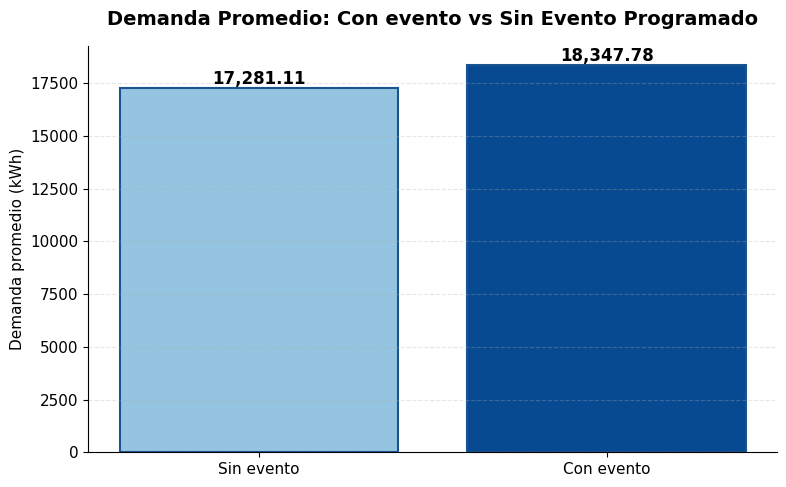


PATRONES OBSERVADOS:
1. La demanda con evento programado es mayor que sin evento
2. Hay oscilaciones semanales visibles
3. La demanda del día anterior parece relacionada con la de hoy

HIPÓTESIS:
El evento programado, el día de la semana y la demanda previa podrían ser predictores útiles


In [5]:
# COMPARAR DEMANDA CON Y SIN EVENTO PROGRAMADO
promedio_evento = df.groupby("evento_programado")["demanda_kwh"].mean()

print("DEMANDA PROMEDIO POR EVENTO PROGRAMADO:")
print("=" * 50)
print(f"   Sin evento (0): {promedio_evento[0]:,.2f} kWh")
print(f"   Con evento (1): {promedio_evento[1]:,.2f} kWh")
print(f"\nDIFERENCIA: {promedio_evento[1] - promedio_evento[0]:,.2f} kWh")
print(f"IMPACTO: {((promedio_evento[1] / promedio_evento[0]) - 1) * 100:.1f}%")

# Gráfico de barras comparativo
fig, ax = plt.subplots(figsize=(8, 5))
colores = plt.cm.Blues(np.linspace(0.4, 0.9, 2))   # más oscuro = más demanda
barras = ax.bar(['Sin evento', 'Con evento'],
                [promedio_evento[0], promedio_evento[1]],
                color=colores, edgecolor='#1a5490', linewidth=1.5)

for barra, valor in zip(barras, [promedio_evento[0], promedio_evento[1]]):
    ax.text(barra.get_x() + barra.get_width()/2., barra.get_height(),
            f'{valor:,.2f}', ha='center', va='bottom',
            fontsize=12, fontweight='bold')

ax.set_title('Demanda Promedio: Con evento vs Sin Evento Programado',
             fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Demanda promedio (kWh)', fontsize=11)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')

plt.tight_layout()
plt.show()

#Documentar observaciones
print("\nPATRONES OBSERVADOS:")
print("=" * 50)
print("1. La demanda con evento programado es mayor que sin evento")
print("2. Hay oscilaciones semanales visibles")
print("3. La demanda del día anterior parece relacionada con la de hoy")
print("\nHIPÓTESIS:")
print("El evento programado, el día de la semana y la demanda previa podrían ser predictores útiles")


In [6]:
# CREAR VARIABLES DE REZAGO
#.shift(1) Obtiene demanda de ayer y .shift(7) la de hace 7 dias

df["lag_1"] = df["demanda_kwh"].shift(1)
df["lag_7"] = df["demanda_kwh"].shift(7)

print("VARIABLES DE REZAGO:")
print("=" * 70)
print(df[["fecha", "demanda_kwh", "lag_1", "lag_7"]].head(10).to_string())



VARIABLES DE REZAGO:
       fecha  demanda_kwh     lag_1     lag_7
0 2026-01-01     17856.31       NaN       NaN
1 2026-01-02     17379.10  17856.31       NaN
2 2026-01-03     15720.70  17379.10       NaN
3 2026-01-04     15694.05  15720.70       NaN
4 2026-01-05     16505.77  15694.05       NaN
5 2026-01-06     16937.36  16505.77       NaN
6 2026-01-07     17456.69  16937.36       NaN
7 2026-01-08     16568.10  17456.69  17856.31
8 2026-01-09     15495.83  16568.10  17379.10
9 2026-01-10     15370.24  15495.83  15720.70


In [7]:
# CREAR MEDIA MOVIL SIN FUGA
#.shift(1)  para excluir el dia actual
#.rolling(window=7) para obtener los ultimos 7 dias
df["media_movil_7"] = (
    df["demanda_kwh"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

print("MEDIA MOVIL DE 7 DÍAS :")
print("=" * 80)
print(df[["fecha", "demanda_kwh", "lag_1", "media_movil_7"]].head(12).to_string())

# Comprobación numérica
manual = df["demanda_kwh"].iloc[3:10].mean()
assert np.isclose(df.loc[10, "media_movil_7"], manual)

print("\nVERIFICACION DE NO FUGA:")
print("   • media_movil_7 en la fila 10 = promedio de demanda_kwh de filas 3-9")
print(f"   • Promedio manual filas 3-9: {manual:,.2f} | media_movil_7 fila 10: {df.loc[10, 'media_movil_7']:,.2f}")
print("   • No incluye demanda_kwh de fila 10 (el día actual)")
print("   • Por lo tanto, está disponible antes de predecir")


MEDIA MOVIL DE 7 DÍAS :
        fecha  demanda_kwh     lag_1  media_movil_7
0  2026-01-01     17856.31       NaN            NaN
1  2026-01-02     17379.10  17856.31            NaN
2  2026-01-03     15720.70  17379.10            NaN
3  2026-01-04     15694.05  15720.70            NaN
4  2026-01-05     16505.77  15694.05            NaN
5  2026-01-06     16937.36  16505.77            NaN
6  2026-01-07     17456.69  16937.36            NaN
7  2026-01-08     16568.10  17456.69   16792.854286
8  2026-01-09     15495.83  16568.10   16608.824286
9  2026-01-10     15370.24  15495.83   16339.785714
10 2026-01-11     15652.73  15370.24   16289.720000
11 2026-01-12     16919.53  15652.73   16283.817143

VERIFICACION DE NO FUGA:
   • media_movil_7 en la fila 10 = promedio de demanda_kwh de filas 3-9
   • Promedio manual filas 3-9: 16,289.72 | media_movil_7 fila 10: 16,289.72
   • No incluye demanda_kwh de fila 10 (el día actual)
   • Por lo tanto, está disponible antes de predecir


In [8]:
#ELIMINAR FILAS CON NULOS
print(f"Filas ANTES de eliminar NaN: {len(df)}")


df_modelo = df.dropna(subset=["lag_1", "lag_7", "media_movil_7"]).copy()
df_modelo = df_modelo.reset_index(drop=True)

print(f"Filas DESPUÉS de eliminar NaN: {len(df_modelo)}")
print(f"Filas eliminadas: {len(df) - len(df_modelo)}")
print(f"\nLas filas eliminadas son las primeras que no tienen historial de 7 días")

print(f"\nPrimeras 3 filas del dataset de modelado:")
print(df_modelo.head(3).to_string())


Filas ANTES de eliminar NaN: 180
Filas DESPUÉS de eliminar NaN: 173
Filas eliminadas: 7

Las filas eliminadas son las primeras que no tienen historial de 7 días

Primeras 3 filas del dataset de modelado:
       fecha  demanda_kwh  evento_programado  dia_semana  mes  tendencia_30     lag_1     lag_7  media_movil_7
0 2026-01-08     16568.10                  0           3    1           NaN  17456.69  17856.31   16792.854286
1 2026-01-09     15495.83                  0           4    1           NaN  16568.10  17379.10   16608.824286
2 2026-01-10     15370.24                  0           5    1           NaN  15495.83  15720.70   16339.785714


In [9]:
#DEFINIR VARIABLES PREDICTORAS (X) Y OBJETIVO (y)

features = [
    "dia_semana",         # Día de la semana (0-6)
    "mes",                # Mes del año (1-12)
    "evento_programado",  # ¿Hay evento programado? (0/1)
    "lag_1",              # Demanda de ayer
    "lag_7",              # Demanda de hace 7 días
    "media_movil_7"       # Promedio de últimos 7 días (excluyendo hoy)
]

X = df_modelo[features]
y = df_modelo["demanda_kwh"]

print("VARIABLES DEFINIDAS:")
print("=" * 60)
print(f"Variables predictoras (X): {len(features)}")
for i, f in enumerate(features, 1):
    print(f"   {i}. {f}")
print(f"\nVariable objetivo (y): demanda_kwh")
print(f"\nDimensiones:")
print(f"   X: {X.shape}")
print(f"   y: {y.shape}")


VARIABLES DEFINIDAS:
Variables predictoras (X): 6
   1. dia_semana
   2. mes
   3. evento_programado
   4. lag_1
   5. lag_7
   6. media_movil_7

Variable objetivo (y): demanda_kwh

Dimensiones:
   X: (173, 6)
   y: (173,)


In [10]:
#SPLIT TEMPORAL 80/20

corte = int(len(df_modelo) * 0.80)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]

y_train = y.iloc[:corte]
y_test = y.iloc[corte:]

fecha_test = df_modelo["fecha"].iloc[corte:]

print("SPLIT TEMPORAL 80/20")
print("=" * 60)
print(f"Total de registros: {len(df_modelo)}")
print(f"Entrenamiento: {len(X_train)} registros (80%)")
print(f"Prueba: {len(X_test)} registros (20%)")

print(f"\nRango de ENTRENAMIENTO:")
print(f"   Desde: {df_modelo['fecha'].iloc[0]}")
print(f"   Hasta: {df_modelo['fecha'].iloc[corte-1]}")

print(f"\nRango de PRUEBA:")
print(f"   Desde: {df_modelo['fecha'].iloc[corte]}")
print(f"   Hasta: {df_modelo['fecha'].iloc[-1]}")

# Verificar que no hay solapamiento
print(f"\nVERIFICACIÓN:")
print(f"   Última fecha entrenamiento: {df_modelo['fecha'].iloc[corte-1]}")
print(f"   Primera fecha prueba: {df_modelo['fecha'].iloc[corte]}")
print(f"   ¿Prueba después de entrenamiento? {df_modelo['fecha'].iloc[corte] > df_modelo['fecha'].iloc[corte-1]}")


SPLIT TEMPORAL 80/20
Total de registros: 173
Entrenamiento: 138 registros (80%)
Prueba: 35 registros (20%)

Rango de ENTRENAMIENTO:
   Desde: 2026-01-08 00:00:00
   Hasta: 2026-05-25 00:00:00

Rango de PRUEBA:
   Desde: 2026-05-26 00:00:00
   Hasta: 2026-06-29 00:00:00

VERIFICACIÓN:
   Última fecha entrenamiento: 2026-05-25 00:00:00
   Primera fecha prueba: 2026-05-26 00:00:00
   ¿Prueba después de entrenamiento? True


In [11]:
# CONSTRUIR BASELINE
# Estrategia: predecir siempre la media del conjunto de entrenamiento

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

pred_baseline = baseline.predict(X_test)

# Calcular métricas del baseline
mae_base = mean_absolute_error(y_test, pred_baseline)
rmse_base = mean_squared_error(y_test, pred_baseline) ** 0.5
r2_base = r2_score(y_test, pred_baseline)

print("BASELINE")
print("=" * 60)
print(f"Media del entrenamiento: {y_train.mean():,.2f} kWh")
print(f"\nMÉTRICAS DEL BASELINE:")
print(f"   MAE:  {mae_base:,.2f} kWh")
print(f"   RMSE: {rmse_base:,.2f} kWh")
print(f"   R²:   {r2_base:.4f}")


BASELINE
Media del entrenamiento: 17,281.82 kWh

MÉTRICAS DEL BASELINE:
   MAE:  1,194.57 kWh
   RMSE: 1,391.68 kWh
   R²:   -1.9384


In [12]:
#ENTRENAR REGRESIÓN LINEAL

modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Predecir sobre el conjunto de prueba
pred = modelo.predict(X_test)

# Calcular métricas
mae = mean_absolute_error(y_test, pred)
rmse = mean_squared_error(y_test, pred) ** 0.5
r2 = r2_score(y_test, pred)

print("REGRESIÓN LINEAL")
print("=" * 60)
print(f"\nMÉTRICAS DEL MODELO:")
print(f"   MAE:  {mae:,.2f} kWh")
print(f"   RMSE: {rmse:,.2f} kWh")
print(f"   R²:   {r2:.4f}")


REGRESIÓN LINEAL

MÉTRICAS DEL MODELO:
   MAE:  298.77 kWh
   RMSE: 378.72 kWh
   R²:   0.7824


In [13]:
# TABLA COMPARATIVA: BASELINE vs MODELO

comparacion = pd.DataFrame({
    "Modelo": ["Baseline (media)", "Regresión Lineal"],
    "MAE": [mae_base, mae],
    "RMSE": [rmse_base, rmse],
    "R²": [r2_base, r2]
})

print("COMPARACIÓN BASELINE vs MODELO:")
print("=" * 70)
print(comparacion.to_string(index=False))

# Calcular mejora
mejora_mae = ((mae_base - mae) / mae_base) * 100
mejora_rmse = ((rmse_base - rmse) / rmse_base) * 100

print(f"\nMEJORAS DEL MODELO vs BASELINE:")
print(f"   MAE:  {mejora_mae:.1f}% de mejora")
print(f"   RMSE: {mejora_rmse:.1f}% de mejora")


COMPARACIÓN BASELINE vs MODELO:
          Modelo         MAE        RMSE        R²
Baseline (media) 1194.572994 1391.676369 -1.938436
Regresión Lineal  298.765002  378.724565  0.782386

MEJORAS DEL MODELO vs BASELINE:
   MAE:  75.0% de mejora
   RMSE: 72.8% de mejora


In [14]:
# COEFICIENTES DEL MODELO

coeficientes = pd.DataFrame({
    "variable": features,
    "coeficiente": modelo.coef_
}).sort_values("coeficiente", key=abs, ascending=False)

print("COEFICIENTES DEL MODELO:")
print("=" * 60)
print(coeficientes.to_string(index=False))

print(f"\nIntercepto (b0): {modelo.intercept_:,.2f} kWh")
print("\nINTERPRETACIÓN:")
print("   • Coeficiente positivo: la variable aumenta la demanda")
print("   • Coeficiente negativo: la variable disminuye la demanda")
print("   • El valor indica cuánto cambia demanda_kwh por cada unidad de la variable")


COEFICIENTES DEL MODELO:
         variable  coeficiente
evento_programado  1031.576833
       dia_semana  -153.338914
              mes   125.866540
            lag_1     0.309187
            lag_7     0.273418
    media_movil_7     0.056263

Intercepto (b0): 6,152.48 kWh

INTERPRETACIÓN:
   • Coeficiente positivo: la variable aumenta la demanda
   • Coeficiente negativo: la variable disminuye la demanda
   • El valor indica cuánto cambia demanda_kwh por cada unidad de la variable


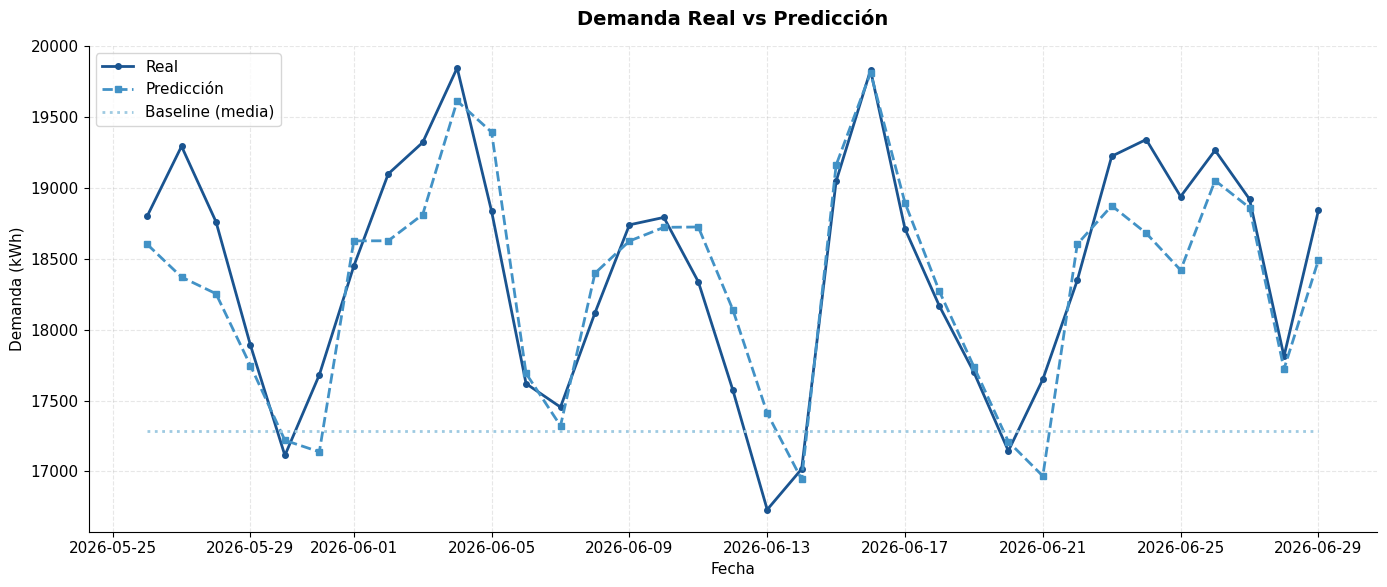

OBSERVACIONES:
   • El modelo sigue la tendencia general
   • Hay desviaciones en días específicos
   • Los errores grandes podrían investigarse


In [15]:
# GRÁFICO: Real vs Predicción (temporal)

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(fecha_test, y_test.values,
        label='Real', color='#1a5490', linewidth=2, marker='o', markersize=4)
ax.plot(fecha_test, pred,
        label='Predicción', color='#4292c6', linewidth=2,
        linestyle='--', marker='s', markersize=4)
ax.plot(fecha_test, pred_baseline,
        label='Baseline (media)', color='#9ecae1', linewidth=2, linestyle=':')

ax.set_title('Demanda Real vs Predicción',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Fecha', fontsize=11)
ax.set_ylabel('Demanda (kWh)', fontsize=11)
ax.legend(loc='upper left', fontsize=11)
ax.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

print("OBSERVACIONES:")
print(f"   • El modelo sigue la tendencia general")
print(f"   • Hay desviaciones en días específicos")
print(f"   • Los errores grandes podrían investigarse")


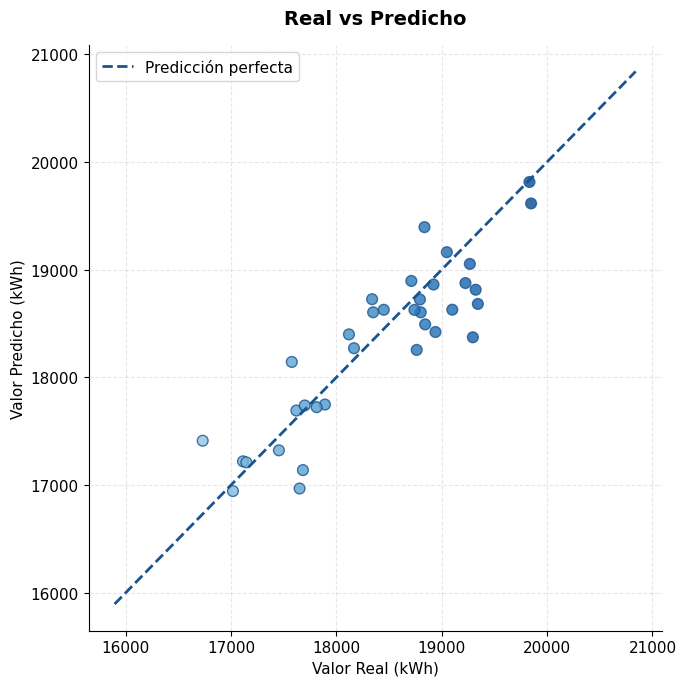

OBSERVACIONES:
   • Si los puntos están sobre la línea azul: predicción perfecta
   • Si están dispersos: mayor error
   • Si hay patrón: el modelo tiene sesgo


In [16]:
# GRÁFICO: Real vs Predicho

fig, ax = plt.subplots(figsize=(7, 7))

# más oscuro = mayor demanda real
colores = plt.cm.Blues(0.4 + 0.5 * (y_test.values - y_test.min()) / (y_test.max() - y_test.min()))
ax.scatter(y_test, pred, alpha=0.8, color=colores, edgecolors='#1a5490', s=60)

# Línea de referencia ideal (y = x)
lim_min = min(y_test.min(), pred.min()) * 0.95
lim_max = max(y_test.max(), pred.max()) * 1.05
ax.plot([lim_min, lim_max], [lim_min, lim_max],
        color='#1a5490', linestyle='--', linewidth=2, label='Predicción perfecta')

ax.set_xlabel('Valor Real (kWh)', fontsize=11)
ax.set_ylabel('Valor Predicho (kWh)', fontsize=11)
ax.set_title('Real vs Predicho', fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

print("OBSERVACIONES:")
print("   • Si los puntos están sobre la línea azul: predicción perfecta")
print("   • Si están dispersos: mayor error")
print("   • Si hay patrón: el modelo tiene sesgo")

In [17]:
# ANÁLISIS DE RESIDUOS

resultados = pd.DataFrame({
    "fecha": fecha_test.values,
    "real": y_test.values,
    "baseline": pred_baseline,
    "prediccion": pred
})
resultados["residuo"] = resultados["real"] - resultados["prediccion"]
resultados["error_abs"] = resultados["residuo"].abs()

print("PRIMEROS 10 RESIDUOS:")
print(resultados.head(10).to_string(index=False))

print(f"\nESTADÍSTICAS DE RESIDUOS:")
print(f"   Residuo promedio: {resultados['residuo'].mean():,.2f} kWh")
print(f"   Residuo mínimo: {resultados['residuo'].min():,.2f} kWh")
print(f"   Residuo máximo: {resultados['residuo'].max():,.2f} kWh")

print(f"\nTOP 5 ERRORES MÁS GRANDES:")
print(resultados.nlargest(5, 'error_abs').to_string(index=False))


PRIMEROS 10 RESIDUOS:
     fecha     real     baseline   prediccion     residuo  error_abs
2026-05-26 18800.00 17281.821304 18603.319450  196.680550 196.680550
2026-05-27 19294.76 17281.821304 18371.300370  923.459630 923.459630
2026-05-28 18761.74 17281.821304 18254.034120  507.705880 507.705880
2026-05-29 17890.43 17281.821304 17746.713486  143.716514 143.716514
2026-05-30 17112.40 17281.821304 17218.995397 -106.595397 106.595397
2026-05-31 17681.47 17281.821304 17137.792835  543.677165 543.677165
2026-06-01 18449.15 17281.821304 18626.926834 -177.776834 177.776834
2026-06-02 19099.73 17281.821304 18627.558135  472.171865 472.171865
2026-06-03 19321.77 17281.821304 18813.055348  508.714652 508.714652
2026-06-04 19847.82 17281.821304 19614.425203  233.394797 233.394797

ESTADÍSTICAS DE RESIDUOS:
   Residuo promedio: 93.58 kWh
   Residuo mínimo: -680.70 kWh
   Residuo máximo: 923.46 kWh

TOP 5 ERRORES MÁS GRANDES:
     fecha     real     baseline   prediccion     residuo  error_abs
202

In [18]:
# GUARDAR RESULTADOS: predicciones.csv y metricas.json

# predicciones.csv
predicciones = pd.DataFrame({
    "fecha": fecha_test.dt.strftime("%Y-%m-%d").values,
    "real": y_test.values,
    "baseline": pred_baseline,
    "prediccion": pred
}).sort_values("fecha").reset_index(drop=True)

predicciones.to_csv("predicciones.csv", index=False, encoding="utf-8")
print(f"Predicciones guardadas: predicciones.csv ({len(predicciones)} filas)")

# metricas.json
metricas = {
    "mae_baseline": round(float(mae_base), 4),
    "mae_modelo": round(float(mae), 4),
    "rmse_modelo": round(float(rmse), 4),
    "r2_modelo": round(float(r2), 4),
    "mejora_mae_pct": round(float(mejora_mae), 2)
}
with open("metricas.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, indent=2)
print("Métricas guardadas: metricas.json")

print("\nCONTENIDO DE metricas.json:")
print(json.dumps(metricas, indent=2))

print("\nPRIMERAS 5 FILAS DE predicciones.csv:")
print(predicciones.head().to_string(index=False))

# Descargar los archivos
from google.colab import files
files.download("predicciones.csv")
files.download("metricas.json")
print("\nArchivos descargados")


Predicciones guardadas: predicciones.csv (35 filas)
Métricas guardadas: metricas.json

CONTENIDO DE metricas.json:
{
  "mae_baseline": 1194.573,
  "mae_modelo": 298.765,
  "rmse_modelo": 378.7246,
  "r2_modelo": 0.7824,
  "mejora_mae_pct": 74.99
}

PRIMERAS 5 FILAS DE predicciones.csv:
     fecha     real     baseline   prediccion
2026-05-26 18800.00 17281.821304 18603.319450
2026-05-27 19294.76 17281.821304 18371.300370
2026-05-28 18761.74 17281.821304 18254.034120
2026-05-29 17890.43 17281.821304 17746.713486
2026-05-30 17112.40 17281.821304 17218.995397


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Archivos descargados


In [19]:
#INTERPRETACIÓN
primera_fecha = fecha_test.iloc[0].strftime("%Y-%m-%d")
ultima_fecha = fecha_test.iloc[-1].strftime("%Y-%m-%d")
veredicto = "Si agrega valor" if mae < mae_base else "No agrega valor"

print("¿EL MODELO AGREGA VALOR FRENTE AL BASELINE?")
print("=" * 70)
print(f"   {veredicto}: MAE {mae_base:,.2f} -> {mae:,.2f} kWh ({mejora_mae:.2f}% mejor), R² = {r2:.2f}")
print(f"   el error medio sigue siendo ~{mae:,.0f} kWh, es una estimación, no una certeza.")

print(f"   Periodo de prueba: {primera_fecha} al {ultima_fecha}")


¿EL MODELO AGREGA VALOR FRENTE AL BASELINE?
   Si agrega valor: MAE 1,194.57 -> 298.77 kWh (74.99% mejor), R² = 0.78
   el error medio sigue siendo ~299 kWh, es una estimación, no una certeza.
   Periodo de prueba: 2026-05-26 al 2026-06-29
